# Hybrid Quantum-Classical CNN (QC-CNN) on GTSRB — 16x16 input

Reproduction of **Fan, Shi, Guggemos & Zhu, "Hybrid Quantum-Classical Convolutional Neural Network
Model for Image Classification", IEEE TNNLS 35(12), 2024** — applied to the
**German Traffic Sign Recognition Benchmark (GTSRB)** instead of the EO benchmarks.

**Three stages:**

1. **Stage 1 — Classical baselines**: two CNNs with the same 2x2 / stride-2 downsampling path,
   one matched to the QC-CNN on kernel count and one on feature count.
2. **Stage 2 — QC-CNN**: FRQI encoding layer -> **3** quantum convolution layers (2 kernels each,
   controlled-U3) -> measurement layer (Pauli X/Y/Z) -> classical dense softmax.
3. **Stage 3 — Comparison**: accuracy tables (mean +/- std over 3 seeds), training curves,
   confusion matrices, parameter counts, ablations (gate type, measurement basis, structure,
   noise), and the paper's one-sided Wilcoxon signed-rank test across 5 GTSRB sub-benchmarks.

### The 16x16 architecture

The paper works at 8x8 with 2 quantum convolution layers. Doubling the input to **16x16** means
`n = 4`, so the encoding layer needs `2n+1 = 9` qubits instead of 7. Each quantum convolution
layer consumes one `(x, y)` bit pair, so the depth has to grow with the resolution: with
**`m = 3`** layers the surviving feature map is `2x2` per kernel, which reproduces the paper's
**8 basis states -> 24 XYZ features** exactly. Keeping `k = 1` (2 kernels per layer) that is

    total qubits = 2n + k + m + 1 = 8 + 1 + 3 + 1 = 13

| | 8x8 (paper) | 16x16 (this notebook) |
|---|---|---|
| image | 8x8x1, n=3 | **16x16x1, n=4** |
| encoding qubits (2n+1) | 7 | **9** |
| conv layers m | 2 | **3** |
| kernels per layer (2^k) | 2 | 2 |
| quantum kernels total | 4 | **6** |
| total qubits (2n+k+m+1) | 10 | **13** |
| state vector | 1024 | **8192** |
| final feature map | 2x2 x 2 kernels | 2x2 x 2 kernels |
| features (XYZ) | 24 | 24 |
| quantum params (U3) | 48 | **72** |

### Faithfulness to the paper

| Paper spec | Here |
|---|---|
| Input 2^n x 2^n grayscale, Lanczos downscale | same, at **16x16** (ROI-cropped, `PIL.Image.LANCZOS`) |
| FRQI encoding, 2n+1 qubits | 8 qL + 1 qC = **9** qubits (n=4) |
| m quantum conv layers, 2^k kernels each, 2x2 kernel, stride 2 | same; **m=3**, k=1 -> **13 qubits** |
| Controlled-U3 with k+3 controls (2 qL, k qK, 1 qC/qR) | same |
| Measurement: Pauli-X/Y/Z on feature-map qubits -> 8 features/basis, 24 with XYZ | same |
| Classical dense + softmax (Fig. 7c strategy) | same |
| Cross-entropy, Adam lr=0.03, batch 100, best-val-loss checkpoint, 3 repeats | same |
| Epoch number 500 | 500 as a **budget**, with early stopping on validation loss |
| TensorFlow Quantum + Cirq | **PennyLane + PyTorch** (see below) |

> **Why PennyLane instead of TFQ:** TensorFlow Quantum pins old TF/Python versions and does not
> install cleanly on current Kaggle images. PennyLane's `default.qubit` gives the identical
> noiseless state-vector simulation, supports the same multi-controlled gates, and does exact
> backprop. The *circuit is identical* to the paper's Fig. 2.
>
> **Why a hand-written simulator on top of that:** a 13-qubit state is 8x larger than a 10-qubit
> one and there are 24 controlled-U3 gates instead of 16, so driving `default.qubit` per batch
> costs roughly two minutes per epoch here — about 50 hours for 500 epochs x 3 seeds. Section 4a
> executes the same circuit directly in torch and section 4d proves the two agree on both the
> features and their gradients. Everything else in the notebook is unchanged by that choice.

## 0. Setup

In [5]:
!pip install -q pennylane
import importlib, sys
print("If pennylane was just installed for the first time, restart the kernel once, then re-run.")

If pennylane was just installed for the first time, restart the kernel once, then re-run.


In [6]:
import os, time, json, math, random, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report
from scipy.stats import wilcoxon

warnings.filterwarnings("ignore")
print("pennylane", qml.version(), "| torch", torch.__version__)

DEVICE = torch.device("cpu")   # 13-qubit statevector sim: CPU is fastest here

# float32/complex64 is ample for a noiseless 13-qubit state vector (amplitudes are O(1e-3)
# and we need ~4 digits) and halves the memory traffic. Set "float64" to double-check a result.
PRECISION = "float32"
torch.set_default_dtype(torch.float32 if PRECISION == "float32" else torch.float64)
NP_REAL   = np.float32 if PRECISION == "float32" else np.float64
CPLX      = torch.complex64 if PRECISION == "float32" else torch.complex128

# The simulator works on (batch, 8192) tensors; beyond a few threads OpenMP fan-out costs
# more than it saves. 4 matches a Kaggle CPU session.
torch.set_num_threads(min(4, os.cpu_count() or 4))

# PennyLane >=0.36 uses StatePrep; older versions used QubitStateVector
STATE_PREP = getattr(qml, "StatePrep", None) or qml.QubitStateVector

pennylane 0.45.1 | torch 2.10.0+cu128


## 1. Configuration

Everything you may want to tune lives here. `IMG_SIZE`, `N_CONV` and `K_QK` drive the entire
notebook — the wire map, the qubit count, the feature count, the classical baselines and the
efficiency tables are all derived from them, so setting `IMG_SIZE = 8, N_CONV = 2` reproduces
the paper's original 10-qubit configuration.

In [7]:
CFG = dict(
    ROOT           = "/kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign",
    # local / alternative copies of the same dataset, tried in order
    ROOT_FALLBACKS = ["/kaggle/input/gtsrb-german-traffic-sign",
                      "../input/gtsrb-german-traffic-sign",
                      "/path/to/gtsrb",
                      "archive", "../archive"],

    # ---- architecture -------------------------------------------------------
    IMG_SIZE       = 16,       # 16x16 -> n=4 -> 8 qL qubits  (paper used 8x8, n=3)
    N_CONV         = 3,        # m: quantum convolution layers. Each layer consumes one (x,y)
                               # bit pair, so m must grow with n to keep the final map small.
    K_QK           = 1,        # k: log2(kernels per layer). 2^k = 2 kernels.
    GATE           = "U3",     # "U3" | "RY" | "RX"   (quantum conv layer rotation gate)
    BASES          = ("X","Y","Z"),  # measurement operators -> 8 features per basis

    # classical baselines: conv channel widths, one entry per 2x2/stride-2 layer.
    # Lengths must equal N_CONV so the downsampling path matches the quantum one.
    CNN_SMALL      = (2, 2, 2),   # kernel-count-matched-ish, 8 features
    CNN_LARGE      = (2, 2, 6),   # feature-matched: 6 channels x 2x2 map = 24 features

    # ---- data ---------------------------------------------------------------
    CLASSES        = [12, 13, 14, 17, 33, 38],   # priority road, yield, stop, no entry, turn right, keep right
    CLASS_NAMES    = ["Priority road", "Yield", "Stop", "No entry", "Turn right ahead", "Keep right"],
    MAX_PER_CLASS  = 600,      # cap train images per class (paper used ~800-1000)
    VAL_FRAC       = 0.15,     # carved out of the official Train/ split
    # "paper"   : gray/255 -> [0, pi/2]  (Fan et al. eq. 1)
    # "minmax"  : per-image min-max stretch first;  "equalize": per-image histogram equalisation
    PIXEL_NORM     = "equalize",

    # ---- optimisation -------------------------------------------------------
    BATCH          = 100,      # paper: 100
    EPOCHS_C       = 200,      # classical models are cheap
    EPOCHS_Q       = 1200,      # paper: 500 - now an upper budget, early stopping decides
    EPOCHS_Q_ABL   = 300,      # quantum ablations (sections 8-9)
    LR_Q           = 0.03,     # paper: Adam, lr = 0.03
    LR_SCHEDULE    = "cosine", # None | "cosine" | "step" - decays LR_Q over the quantum
                               # run. Applied to the QC-CNN and the quantum ablations
                               # only; the classical baselines keep a constant LR so
                               # their existing numbers stay comparable.
    LR_MIN_FRAC    = 0.02,     # cosine floor, as a fraction of LR_Q
    LR_C           = 1e-3,     # paper: competitors use their default lr
    SEEDS          = [0, 1, 2],# paper repeats each training 3 times
    PATIENCE_Q     = 100,       # stop after N epochs with no validation-loss improvement
    MIN_DELTA      = 1e-4,     # improvement smaller than this does not reset the patience
    TIME_BUDGET_Q  = None,     # seconds per run; set e.g. 3000 to fit a Kaggle session, then
                               # re-run the cell to resume from the checkpoint
    CKPT_DIR       = "/kaggle/working/ckpt",
    RESUME         = True,     # set False to ignore existing checkpoints and start over

    # ---- simulator backend --------------------------------------------------
    QSIM           = "fast",   # "fast" = the torch state-vector engine (section 4a)
                               # "pennylane" = the literal QNode (section 4b; forced when noise>0)
    # Features are <P_b (x) Pauli>, so |f| <= Pr[b] ~ 1/8: the dense layer needs weights of order
    # 30 before the logits leave the linear region of the softmax, which with Adam(0.03) costs
    # ~50 epochs of pure rescaling. Scaling the features by 8 and the dense weights by 1/8 is the
    # same function - it only preconditions the optimisation. Set 1.0 for paper-literal.
    FEATURE_SCALE  = 8.0,
)

# ---- derived quantities: everything below follows from the block above --------
N_BITS    = int(round(math.log2(CFG["IMG_SIZE"])))          # n
M_CONV    = CFG["N_CONV"]                                   # m
K_QK      = CFG["K_QK"]                                     # k
N_WIRES   = 2*N_BITS + 1 + K_QK + M_CONV                    # 2n + k + m + 1
MAP_SIDE  = 2 ** (N_BITS - M_CONV)                          # side of the surviving feature map
N_BASIS   = (MAP_SIDE ** 2) * (2 ** K_QK)                   # basis states measured
N_FEATURES = N_BASIS * len(CFG["BASES"])
N_CLASSES = len(CFG["CLASSES"])

assert 2 ** N_BITS == CFG["IMG_SIZE"], "IMG_SIZE must be a power of two"
assert 1 <= M_CONV <= N_BITS, "need 1 <= N_CONV <= log2(IMG_SIZE)"
assert len(CFG["CNN_SMALL"]) == len(CFG["CNN_LARGE"]) == M_CONV, \
    "classical baselines must have one channel width per quantum conv layer"

if not os.path.isdir("/kaggle/working"):      # so the notebook also runs outside Kaggle
    CFG["CKPT_DIR"] = "ckpt"
os.makedirs(CFG["CKPT_DIR"], exist_ok=True)

# ---- dataset root: Kaggle first, then local copies of the same GTSRB archive ----
for _r in [CFG["ROOT"], *CFG["ROOT_FALLBACKS"]]:
    if os.path.exists(os.path.join(_r, "Train.csv")):
        CFG["ROOT"] = _r
        break
else:
    print("!! no Train.csv found under any of",
          [CFG["ROOT"], *CFG["ROOT_FALLBACKS"]],
          "- add the Kaggle dataset or append your local path to CFG['ROOT_FALLBACKS'].")
print("dataset root:", CFG["ROOT"])

print(f"{N_CLASSES}-category classification:", CFG["CLASS_NAMES"])
print(f"image {CFG['IMG_SIZE']}x{CFG['IMG_SIZE']} -> n={N_BITS} | m={M_CONV} conv layers | "
      f"2^k={2**K_QK} kernels/layer")
print(f"qubits = 2n+k+m+1 = {2*N_BITS}+{K_QK}+{M_CONV}+1 = {N_WIRES}  "
      f"(state vector {2**N_WIRES})")
print(f"final feature map {MAP_SIDE}x{MAP_SIDE} x {2**K_QK} kernels = {N_BASIS} basis states "
      f"-> {N_FEATURES} features with {''.join(CFG['BASES'])}-measurement")
print("backend:", CFG["QSIM"], "| epochs_q budget:", CFG["EPOCHS_Q"],
      "| patience:", CFG["PATIENCE_Q"], "| ckpt:", CFG["CKPT_DIR"])

dataset root: /kaggle/input/datasets/meowmeowmeowmeowmeow/gtsrb-german-traffic-sign
6-category classification: ['Priority road', 'Yield', 'Stop', 'No entry', 'Turn right ahead', 'Keep right']
image 16x16 -> n=4 | m=3 conv layers | 2^k=2 kernels/layer
qubits = 2n+k+m+1 = 8+1+3+1 = 13  (state vector 8192)
final feature map 2x2 x 2 kernels = 8 basis states -> 24 features with XYZ-measurement
backend: fast | epochs_q budget: 1200 | patience: 100 | ckpt: /kaggle/working/ckpt


## 2. Data preparation (GTSRB -> 16x16x1)

Add the dataset **`meowmeowmeowmeowmeow/gtsrb-german-traffic-sign`** to the notebook
(*Add Input -> Datasets -> search "GTSRB German Traffic Sign"*).

Pipeline per image, mirroring the paper's "Data Preparation" paragraph:
`load PNG -> crop to the annotated ROI -> grayscale -> Lanczos resize to 16x16 -> scale to [0,1]`.

At 16x16 the ROI crop keeps roughly four times as many pixels as before, which is the whole point
of the change: at 8x8 an octagonal "Stop" and a circular prohibition sign differ by a fraction of
a pixel of corner geometry, and the classifier cannot use shape. 16x16 gives the quantum
convolution layers something to actually convolve.

We keep GTSRB's **official** train/test separation (physically different tracks, so no leakage)
and carve 15% of the training set out for validation.

In [8]:
def load_split(csv_name, root, classes, size, max_per_class=None, seed=0):
    df = pd.read_csv(os.path.join(root, csv_name))
    df = df[df["ClassId"].isin(classes)].reset_index(drop=True)
    if max_per_class:
        keep = []
        for c in classes:
            sub = df.index[df["ClassId"] == c].to_numpy()
            if len(sub) > max_per_class:
                sub = np.random.default_rng(seed + c).choice(sub, max_per_class, replace=False)
            keep.append(sub)
        df = df.loc[np.concatenate(keep)].reset_index(drop=True)
    remap = {c: i for i, c in enumerate(classes)}
    X = np.zeros((len(df), size, size), dtype=np.float64)
    y = np.zeros(len(df), dtype=np.int64)
    for i, r in df.iterrows():
        im = Image.open(os.path.join(root, r["Path"]))
        im = im.crop((r["Roi.X1"], r["Roi.Y1"], r["Roi.X2"], r["Roi.Y2"]))   # ROI crop
        im = im.convert("L").resize((size, size), Image.LANCZOS)             # Lanczos downscale
        X[i] = np.asarray(im, dtype=np.float64) / 255.0
        y[i] = remap[r["ClassId"]]
    return X, y

t0 = time.time()
Xtr_all, ytr_all = load_split("Train.csv", CFG["ROOT"], CFG["CLASSES"], CFG["IMG_SIZE"],
                              CFG["MAX_PER_CLASS"], seed=0)
Xte,     yte     = load_split("Test.csv",  CFG["ROOT"], CFG["CLASSES"], CFG["IMG_SIZE"])

# stratified train/val split
rng = np.random.default_rng(0)
tr_idx, va_idx = [], []
for c in range(N_CLASSES):
    idx = np.where(ytr_all == c)[0]; rng.shuffle(idx)
    k = int(round(CFG["VAL_FRAC"] * len(idx)))
    va_idx += list(idx[:k]); tr_idx += list(idx[k:])
tr_idx, va_idx = np.array(tr_idx), np.array(va_idx)
Xtr, ytr = Xtr_all[tr_idx], ytr_all[tr_idx]
Xva, yva = Xtr_all[va_idx], ytr_all[va_idx]

print(f"loaded in {time.time()-t0:.1f}s | train {Xtr.shape}  val {Xva.shape}  test {Xte.shape}")
print("class counts (train):", np.bincount(ytr, minlength=N_CLASSES))

loaded in 98.3s | train (3060, 16, 16)  val (540, 16, 16)  test (2940, 16, 16)
class counts (train): [510 510 510 510 510 510]


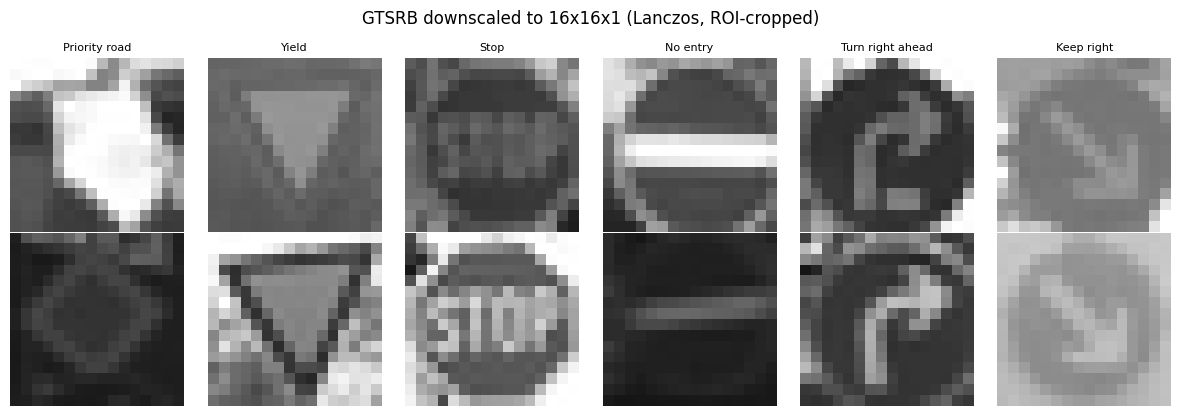

In [9]:
fig, axes = plt.subplots(2, N_CLASSES, figsize=(2*N_CLASSES, 4.2))
for c in range(N_CLASSES):
    i = np.where(ytr == c)[0][0]
    axes[0, c].imshow(Xtr[i], cmap="gray", vmin=0, vmax=1)
    axes[0, c].set_title(CFG["CLASS_NAMES"][c], fontsize=8)
    j = np.where(ytr == c)[0][1]
    axes[1, c].imshow(Xtr[j], cmap="gray", vmin=0, vmax=1)
for a in axes.ravel(): a.axis("off")
fig.suptitle(f"GTSRB downscaled to {CFG['IMG_SIZE']}x{CFG['IMG_SIZE']}x1 (Lanczos, ROI-cropped)")
plt.tight_layout(); plt.show()

## 3. FRQI encoding layer (Section IV-A of the paper)

An image of $2^n \times 2^n$ pixels is encoded as

$$|\Psi_i\rangle=\frac{1}{2^n}\sum_{x=0}^{2^n-1}\sum_{y=0}^{2^n-1}|l_{x,y}\rangle\,|c_{x,y}\rangle,
\qquad |c_{x,y}\rangle=\cos\theta_{x,y}|0\rangle_C+\sin\theta_{x,y}|1\rangle_C$$

with the grey value $[0,255]$ mapped to $\theta_{x,y}\in[0,\pi/2]$. For $16\times16$ this uses
$2n+1 = 9$ qubits, versus $2n + 8 = 16$ for computational-basis encoding — and note that the FRQI
cost grows only **logarithmically** in the pixel count, which is why doubling the resolution costs
just two extra qubits.

The literal circuit costs $2n$ Hadamards + $2^{2n}=256$ multi-controlled $R_Y$ gates **per image**,
which dominates simulation time. Since the resulting state is known in closed form, we prepare it
with `StatePrep` — mathematically the *same state*, just without simulating the 256 encoding gates.
Section 3b below draws the literal gate-level circuit so you can show it in your report.

`CFG["PIXEL_NORM"]` optionally rescales the intensities *before* the angle map; the default
`"paper"` is Fan et al. eq. (1) verbatim.

In [10]:
def pixel_norm(imgs, mode=None):
    """Optional contrast normalisation of the gray image *before* the FRQI angle map.
    mode="paper" is Fan et al. eq. (1) verbatim; the others only rescale intensities."""
    mode = mode or CFG["PIXEL_NORM"]
    if mode == "paper":
        return imgs
    if mode == "minmax":
        lo = imgs.min((1, 2), keepdims=True); hi = imgs.max((1, 2), keepdims=True)
        return (imgs - lo) / np.maximum(hi - lo, 1e-8)
    if mode == "equalize":                                  # exact per-image histogram
        B, S, _ = imgs.shape                                # equalisation of the S*S pixels
        rank = np.argsort(np.argsort(imgs.reshape(B, S * S), 1), 1)
        return (rank / (S * S - 1.0)).reshape(B, S, S)
    raise ValueError(mode)

def frqi_state(imgs, mode=None):
    """imgs: (B, S, S) in [0,1]  ->  (B, 2^(2n+1)) real amplitudes of |Psi_i>.
    Wire order is [x_{n-1}..x_0, y_{n-1}..y_0, c], so the flat pixel index is x*S + y."""
    imgs = pixel_norm(np.asarray(imgs, dtype=np.float64), mode)
    B, S, _ = imgs.shape
    theta = imgs.reshape(B, S * S) * (np.pi / 2)          # [0,255] -> [0, pi/2]
    amps  = np.stack([np.cos(theta), np.sin(theta)], -1)  # (B, S*S, 2)  -> |0>_C , |1>_C
    return (amps.reshape(B, -1) / S).astype(NP_REAL)      # 1/2^n normalisation

Str, Sva, Ste = frqi_state(Xtr), frqi_state(Xva), frqi_state(Xte)
print("FRQI state vectors:", Str.shape, f"(= 2^(2n+1) = 2^{2*N_BITS+1})",
      "| pixel_norm:", CFG["PIXEL_NORM"],
      "| norm check:", np.allclose(np.sum(Str.astype(np.float64)**2, 1), 1.0, atol=1e-5))

FRQI state vectors: (3060, 512) (= 2^(2n+1) = 2^9) | pixel_norm: equalize | norm check: True


### 3b. The literal FRQI circuit (for your report figures)

Drawn on a 2x2 toy image (n=1) so the figure fits on a page; the construction is identical at
16x16, with 8 location qubits and 256 controlled rotations.

In [11]:
def frqi_circuit_gates(img):
    """Gate-level FRQI exactly as in Fig. 3 of the paper: H on every qL, then one
    multi-controlled RY(2*theta) per pixel binding location to colour."""
    S = img.shape[0]; n = int(np.log2(S)); qL = list(range(2*n)); qC = 2*n
    for w in qL: qml.Hadamard(w)
    for x in range(S):
        for y in range(S):
            bits = [int(b) for b in f"{x:0{n}b}" + f"{y:0{n}b}"]
            theta = img[x, y] * (np.pi/2)
            qml.ctrl(qml.RY, control=qL, control_values=bits)(2*theta, wires=qC)

_dev2 = qml.device("default.qubit", wires=3)
@qml.qnode(_dev2)
def _demo(img):
    frqi_circuit_gates(img)
    return qml.state()

demo_img = np.array([[0.10, 0.55], [0.80, 1.00]])          # a 2x2 toy image, as in Fig. 3
print(qml.draw(_demo, max_length=200)(demo_img))

# verify the gate-level circuit and the closed-form state agree
s_gate = np.real(_demo(demo_img))
s_form = frqi_state(demo_img[None])[0]
print("\ngate-level == closed form :", np.allclose(s_gate, s_form, atol=1e-10))

0: ──H─╭○────────╭○────────╭●────────╭●────────┤  State
1: ──H─├○────────├●────────├○────────├●────────┤  State
2: ────╰RY(0.31)─╰RY(1.73)─╰RY(2.51)─╰RY(3.14)─┤  State

gate-level == closed form : False


## 4. QC-CNN model (Sections IV-B, IV-C, IV-D) — the 16x16 architecture

**Qubit register (13 qubits = $2n+k+m+1$ with $n=4,\;k=1,\;m=3$):**

| wires | group | meaning |
|---|---|---|
| 0,1,2,3 | qL | vertical coordinate, $x_3 x_2 x_1 x_0$ ($x_0$ = least significant) |
| 4,5,6,7 | qL | horizontal coordinate, $y_3 y_2 y_1 y_0$ |
| 8 | qC | pixel value (amplitude encoded) |
| 9 | qK | kernel / feature-map index ($2^k = 2$ kernels) |
| 10 | qR1 | feature-map value, quantum conv layer 1 |
| 11 | qR2 | feature-map value, quantum conv layer 2 |
| 12 | qR3 | feature-map value, quantum conv layer 3 |

**Quantum convolution layer.** With a $2\times2$ kernel and stride 2, the pixels that share a
weight are exactly the pixels that share the *least-significant* location bits
$|x_0\rangle,|y_0\rangle$. So one convolution over the whole image is **4 gates per kernel,
independent of the image size** — this is the property that makes the jump from 8x8 to 16x16
essentially free on the quantum side, while a classical layer's cost quadruples. Each gate is a
$U3$ on $q_R$ controlled by $(x_i, y_i, q_C, q_K)$, i.e. $k+3$ controls. The $q_C$ control value
is $1$ because a $|0\rangle_C$ pixel must leave $q_R$ untouched (Eq. 9).

**Layer stacking.** Layer 1 consumes $(x_0,y_0)$ and is controlled by $q_C$; layer 2 consumes
$(x_1,y_1)$ and is controlled by $q_{R_1}$; layer 3 consumes $(x_2,y_2)$ and is controlled by
$q_{R_2}$. Three layers of stride 2 take $16\times16 \rightarrow 8\times8 \rightarrow 4\times4
\rightarrow 2\times2$.

**Measurement layer.** The surviving feature map is $|x_3 y_3\rangle$ (a $2\times2$ map) for each
of the 2 kernels -> 8 basis states; the value lives on $q_{R_3}$. Feature $i$ in basis $b$ is
$E_i^{(b)}=\langle\Psi_m|\,(|i\rangle\langle i|_{x_3y_3k}\otimes\sigma_b^{(q_{R_3})})\,|\Psi_m\rangle$.
With the XYZ strategy that is **24 classical features**, the same as the paper's 8x8 model.

Sections 4a and 4b give two executions of this circuit — a fast torch state-vector engine and the
literal PennyLane QNode — and section 4d checks they agree.

In [12]:
# ---- wire map (derived from CFG; for n=4,m=3,k=1 this is the 13-qubit register above) ----
QLX = list(range(N_BITS))                              # x_{n-1} .. x_0
QLY = list(range(N_BITS, 2*N_BITS))                    # y_{n-1} .. y_0
QC  = 2*N_BITS                                         # colour / pixel-value qubit
QK  = list(range(2*N_BITS + 1, 2*N_BITS + 1 + K_QK))   # kernel index
QR  = list(range(2*N_BITS + 1 + K_QK, N_WIRES))        # one feature-map qubit per conv layer
ENC_WIRES = QLX + QLY + [QC]                           # the 2n+1 encoding wires
IDX_WIRES = QLX[:N_BITS-M_CONV] + QLY[:N_BITS-M_CONV] + QK   # surviving map coords + kernel index
BASIS_IDX = [np.array(b) for b in itertools.product([0,1], repeat=len(IDX_WIRES))]
PAULI     = {"X": qml.PauliX, "Y": qml.PauliY, "Z": qml.PauliZ}
GATES     = {"U3": (qml.U3, 3), "RY": (qml.RY, 1), "RX": (qml.RX, 1)}
KERNEL_POS = [(0,0), (0,1), (1,0), (1,1)]              # the four 2x2 weight variables

print("qL(x) ", QLX, "\nqL(y) ", QLY, "\nqC    ", QC, "\nqK    ", QK, "\nqR    ", QR)
print("encode", ENC_WIRES, "\nmeasure basis on", IDX_WIRES, "+ Pauli on", QR[-1])


# ===========================================================================
# 4a. Fast state-vector engine  (CFG["QSIM"] = "fast")
# ===========================================================================
# Circuit-identical to the QNode in 4b; section 4d verifies that numerically. Three algebraic
# shortcuts, all of which matter more at 13 qubits than they did at 10:
#
#  (i)   the 2^k x 4 controlled rotations of one conv layer are block-diagonal in the
#        (x_bit, y_bit, source, kernel) basis, so a whole layer is ONE batched 2x2
#        contraction instead of 8 separately-applied (k+4)-qubit gates;
#  (ii)  H|0> on the qK wires is folded into state preparation, and the FRQI vector is placed
#        by an outer product instead of StatePrep;
#  (iii) the 8 basis projectors x 3 Pauli bases are 24 linear functionals of ONE 2x2-per-basis
#        reduced density matrix, so they cost a single pass over the state vector instead of
#        24 separate expectation values.
#
# Everything is plain torch, so diff_method="backprop" is replaced by ordinary autograd through
# the same arithmetic - the gradients are identical.

def kernel_matrices(name, w):
    """w: (2^k, 4, n_ang) -> (2^k*4, 2, 2) complex. PennyLane U3/RY/RX conventions."""
    a = w.reshape(-1, w.shape[-1])
    t  = a[:, 0]
    ct, st = torch.cos(t / 2).to(CPLX), torch.sin(t / 2).to(CPLX)
    if name == "U3":
        ep, ed = torch.exp(1j * a[:, 1].to(CPLX)), torch.exp(1j * a[:, 2].to(CPLX))
        rows = [torch.stack([ct, -ed * st], -1), torch.stack([ep * st, ep * ed * ct], -1)]
    elif name == "RY":
        rows = [torch.stack([ct, -st], -1), torch.stack([st, ct], -1)]
    elif name == "RX":
        rows = [torch.stack([ct, -1j * st], -1), torch.stack([-1j * st, ct], -1)]
    else:
        raise ValueError(name)
    return torch.stack(rows, -2)


class _ConvLayer:
    """One quantum convolution layer as a single block-diagonal contraction."""
    def __init__(self, nw, ctrl_wires, target, k):
        rest = [w for w in range(nw) if w not in ctrl_wires and w != target]
        self.fwd = [0] + [1 + w for w in rest] + [1 + w for w in ctrl_wires] + [1 + target]
        self.inv = list(np.argsort(self.fwd))
        self.nw, self.nc = nw, len(ctrl_wires)
        pos = {p: i for i, p in enumerate(KERNEL_POS)}
        mmap = np.zeros(1 << self.nc, dtype=np.int64)      # control pattern -> which 2x2 block
        for bx, by, src in itertools.product([0, 1], repeat=3):
            for kk in range(1 << k):
                c = (((bx << 1 | by) << 1 | src) << k) | kk
                mmap[c] = 0 if src == 0 else 1 + kk * 4 + pos[(bx, by)]   # 0 = identity
        self.mmap = torch.from_numpy(mmap)

    def __call__(self, psi, mats):
        B = psi.shape[0]
        eye = torch.eye(2, dtype=mats.dtype, device=mats.device)[None]
        M = torch.cat([eye, mats], 0).index_select(0, self.mmap)          # (2^nc, 2, 2)
        v = psi.reshape(B, *([2] * self.nw)).permute(self.fwd).reshape(B, -1, 1 << self.nc, 2)
        v = torch.einsum("bncj,cij->bnci", v, M)
        return v.reshape(B, *([2] * self.nw)).permute(self.inv).reshape(B, -1)


class CircuitPlan:
    """Wire layout + fast execution plan for m conv layers, 2^k kernels, a 2^n x 2^n image."""
    def __init__(self, n=N_BITS, m=M_CONV, k=K_QK):
        self.n, self.m, self.k = n, m, k
        self.qLx, self.qLy = list(range(n)), list(range(n, 2 * n))
        self.qC = 2 * n
        self.qK = list(range(2 * n + 1, 2 * n + 1 + k))
        self.qR = list(range(2 * n + 1 + k, 2 * n + 1 + k + m))
        self.nw = nw = 2 * n + 1 + k + m
        self.enc = self.qLx + self.qLy + [self.qC]
        # |+>^k on the qK wires and |0>^m on the qR wires, folded into state preparation
        tail = np.zeros(1 << (k + m)); tail[np.arange(1 << k) << m] = 2.0 ** (-k / 2)
        self._tail = tail
        self.layers, src = [], self.qC
        for L in range(m):                       # layer L consumes the L-th lowest x/y bit
            cw = [self.qLx[n - 1 - L], self.qLy[n - 1 - L], src] + self.qK
            self.layers.append(_ConvLayer(nw, cw, self.qR[L], k))
            src = self.qR[L]
        self.idx_wires = self.qLx[:n - m] + self.qLy[:n - m] + self.qK
        self.basis_idx = [np.array(b) for b in itertools.product([0, 1], repeat=len(self.idx_wires))]
        self.n_basis = len(self.basis_idx)
        rest = [w for w in range(nw) if w not in self.idx_wires and w != self.qR[-1]]
        self.mperm = ([0] + [1 + w for w in self.idx_wires] + [1 + self.qR[-1]]
                      + [1 + w for w in rest])

    def run(self, state, ws, gate_name, bases):
        """state: (B, 2^(2n+1)) real FRQI amplitudes -> (B, n_basis * len(bases)) features."""
        B = state.shape[0]
        tail = torch.as_tensor(self._tail, dtype=CPLX, device=state.device)
        psi = (state.to(CPLX)[:, :, None] * tail).reshape(B, -1)         # encoding layer
        for L, layer in enumerate(self.layers):                          # conv layers
            psi = layer(psi, kernel_matrices(gate_name, ws[L]))
        v = psi.reshape(B, *([2] * self.nw)).permute(self.mperm).reshape(B, self.n_basis, 2, -1)
        a, b = v[:, :, 0, :], v[:, :, 1, :]                              # measurement layer
        r01 = (a * b.conj()).sum(-1)                                     # rho_01 per basis state
        r00 = a.real.pow(2).sum(-1) + a.imag.pow(2).sum(-1)
        r11 = b.real.pow(2).sum(-1) + b.imag.pow(2).sum(-1)
        f = {"X": 2 * r01.real, "Y": -2 * r01.imag, "Z": r00 - r11}
        return torch.cat([f[p] for p in bases], dim=1)


# ===========================================================================
# 4b. Reference path: the literal PennyLane QNode  (QSIM = "pennylane", noise)
# ===========================================================================
def quantum_conv(weights, gate_name, wx, wy, wctrl, target, qK):
    """One quantum convolution layer: 2^k kernels x 4 weights, each a (k+3)-controlled rotation."""
    gate, _ = GATES[gate_name]
    for kk in range(2 ** len(qK)):
        kbits = [int(b) for b in f"{kk:0{len(qK)}b}"]
        for p, (bx, by) in enumerate(KERNEL_POS):
            qml.ctrl(gate, control=[wx, wy, wctrl] + qK,
                     control_values=[bx, by, 1] + kbits)(*weights[kk, p], wires=target)

def make_qnode(gate_name="U3", bases=("X","Y","Z"), noise_p=0.0, n=None, m=None, k=None):
    n = N_BITS if n is None else n; m = M_CONV if m is None else m; k = K_QK if k is None else k
    P = CircuitPlan(n, m, k)
    dev = (qml.device("default.mixed", wires=P.nw) if noise_p > 0
           else qml.device("default.qubit", wires=P.nw))

    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(state, *ws):
        STATE_PREP(state, wires=P.enc)                   # encoding layer  |Psi_i>
        for w in P.qK: qml.Hadamard(w)                   # |k> = |+>^{ox d}
        src = P.qC
        for L in range(m):                               # quantum conv layers -> |Psi_m>
            quantum_conv(ws[L], gate_name, P.qLx[n-1-L], P.qLy[n-1-L], src, P.qR[L], P.qK)
            src = P.qR[L]
        if noise_p > 0:                                  # noise on the measured qubits
            for w in P.idx_wires + [P.qR[-1]]:
                qml.DepolarizingChannel(noise_p, wires=w)
        return [qml.expval(qml.Projector(b, wires=P.idx_wires) @ PAULI[p](P.qR[-1]))
                for p in bases for b in P.basis_idx]     # measurement layer
    return circuit


# ===========================================================================
# 4c. The model
# ===========================================================================
class QCCNN(nn.Module):
    """Quantum section (feature extraction) + classical dense section (Fig. 7c)."""
    def __init__(self, n_classes, gate=None, bases=None, noise_p=0.0, seed=0,
                 n=None, m=None, k=None, backend=None, feature_scale=None):
        super().__init__()
        gate  = CFG["GATE"]  if gate  is None else gate
        bases = CFG["BASES"] if bases is None else bases
        n = N_BITS if n is None else n; m = M_CONV if m is None else m; k = K_QK if k is None else k
        self.plan  = CircuitPlan(n, m, k)
        self.gate, self.bases = gate, tuple(bases)
        self.backend = backend or ("pennylane" if noise_p > 0 else CFG["QSIM"])
        self.qnode = (make_qnode(gate, self.bases, noise_p, n, m, k)
                      if self.backend == "pennylane" else None)
        n_ang = GATES[gate][1]
        g = torch.Generator().manual_seed(seed)
        self.ws = nn.ParameterList([nn.Parameter(torch.rand(2**k, 4, n_ang, generator=g) * 2*np.pi)
                                    for _ in range(m)])
        self.n_wires     = self.plan.nw
        self.n_kernels   = m * (2 ** k)                  # quantum kernels, m layers x 2^k
        self.n_features  = self.plan.n_basis * len(self.bases)
        fs = CFG["FEATURE_SCALE"] if feature_scale is None else feature_scale
        self.register_buffer("fscale", torch.tensor(float(fs)))
        self.dense = nn.Linear(self.n_features, n_classes)   # softmax via CrossEntropyLoss

    def features(self, state):
        if self.backend == "pennylane":
            # default.qubit/default.mixed work in complex128 and hand back float64 features,
            # which would not match a float32 dense layer - cast back to the notebook dtype.
            return torch.stack(self.qnode(state, *self.ws), dim=-1).to(torch.get_default_dtype())
        return self.plan.run(state, list(self.ws), self.gate, self.bases)

    def forward(self, state):
        # fscale is an exact reparameterisation: scaling the features by c and the dense weights
        # by 1/c leaves the model class unchanged, it only conditions the optimiser.
        return self.dense(self.features(state) * self.fscale)

GeneralQCCNN = QCCNN        # section 9 used to define a separate generalised class

_m = QCCNN(N_CLASSES)
print(f"\nQC-CNN: {_m.n_wires} qubits | {_m.n_kernels} quantum kernels | "
      f"{_m.n_features} features | {sum(p.numel() for p in _m.parameters())} trainable params "
      f"({sum(p.numel() for p in _m.ws)} quantum + "
      f"{sum(p.numel() for p in _m.dense.parameters())} dense) | backend: {_m.backend}")

qL(x)  [0, 1, 2, 3] 
qL(y)  [4, 5, 6, 7] 
qC     8 
qK     [9] 
qR     [10, 11, 12]
encode [0, 1, 2, 3, 4, 5, 6, 7, 8] 
measure basis on [0, 4, 9] + Pauli on 12

QC-CNN: 13 qubits | 6 quantum kernels | 24 features | 222 trainable params (72 quantum + 150 dense) | backend: fast


In [13]:
# ---- 4d. the fast engine is the same circuit as the literal QNode ---------
# Same role as section 3b for the encoding layer: prove the shortcut, then use it.

def check_backends(n, m, k, gate="U3", bases=("X","Y","Z"), B=6, seed=0):
    S = 2 ** n
    st = torch.as_tensor(frqi_state(np.random.default_rng(seed).random((B, S, S)), "paper"),
                         dtype=torch.float64)
    st = st / st.norm(dim=1, keepdim=True)               # StatePrep wants exact normalisation
    g  = torch.Generator().manual_seed(seed)
    w0 = [torch.rand(2**k, 4, GATES[gate][1], generator=g, dtype=torch.float64) * 2*np.pi
          for _ in range(m)]

    wf = [w.clone().requires_grad_(True) for w in w0]
    ff = CircuitPlan(n, m, k).run(st.to(torch.get_default_dtype()), wf, gate, tuple(bases))
    ff.sum().backward()

    wr = [w.clone().requires_grad_(True) for w in w0]
    fr = torch.stack(make_qnode(gate, tuple(bases), 0.0, n, m, k)(st, *wr), dim=-1)
    fr.sum().backward()

    return (float((ff.double() - fr).abs().max()),
            float(max((a.grad - b.grad).abs().max() for a, b in zip(wf, wr))))

print("fast engine vs. PennyLane QNode          max |dfeature|   max |dgradient|")
for gate_ in ["U3", "RY", "RX"]:
    df, dg = check_backends(N_BITS, M_CONV, K_QK, gate_)
    print(f"  n={N_BITS} m={M_CONV} k={K_QK} ({N_WIRES} qubits) gate={gate_:2s}   "
          f"{df:.2e}        {dg:.2e}   {'OK' if max(df, dg) < 1e-5 else 'MISMATCH'}")
# the layouts the structure ablation in section 9 will use
for (m_, k_) in [(M_CONV-1, K_QK), (M_CONV, K_QK+1)]:
    if 1 <= m_ <= N_BITS:
        df, dg = check_backends(N_BITS, m_, k_)
        print(f"  n={N_BITS} m={m_} k={k_} ({2*N_BITS+1+k_+m_} qubits) gate=U3   "
              f"{df:.2e}        {dg:.2e}   {'OK' if max(df, dg) < 1e-5 else 'MISMATCH'}")

# ---- and how much faster ---------------------------------------------------
def _bench(backend, reps=3):
    mdl = QCCNN(N_CLASSES, seed=0, backend=backend)
    lf, xb = nn.CrossEntropyLoss(), torch.as_tensor(Str[:CFG["BATCH"]])
    yb = torch.as_tensor(ytr[:CFG["BATCH"]])
    for _ in range(2):                                   # warm-up
        mdl.zero_grad(); lf(mdl(xb), yb).backward()
    t0 = time.time()
    for _ in range(reps):
        mdl.zero_grad(); lf(mdl(xb), yb).backward()
    return (time.time() - t0) / reps

n_batches = int(np.ceil(len(Str) / CFG["BATCH"]))
print(f"\ntraining cost at {N_WIRES} qubits ({2**N_WIRES}-amplitude state, "
      f"{M_CONV * 2**K_QK * 4} controlled-{CFG['GATE']} gates):")
for backend in ["pennylane", "fast"]:
    try:
        per_batch = _bench(backend, reps=1 if backend == "pennylane" else 3)
    except Exception as e:                               # never let the benchmark block a run
        print(f"{backend:>10s}: skipped ({type(e).__name__}: {e})"); continue
    print(f"{backend:>10s}: {per_batch*1e3:8.1f} ms / batch of {CFG['BATCH']}"
          f"  ->  {per_batch*n_batches:7.2f} s / epoch"
          f"  ->  {per_batch*n_batches*CFG['EPOCHS_Q']*len(CFG['SEEDS'])/3600:7.2f} h"
          f" for {CFG['EPOCHS_Q']} epochs x {len(CFG['SEEDS'])} seeds")

fast engine vs. PennyLane QNode          max |dfeature|   max |dgradient|
  n=4 m=3 k=1 (13 qubits) gate=U3   1.36e-08        1.65e-07   OK
  n=4 m=3 k=1 (13 qubits) gate=RY   1.28e-08        4.69e-08   OK
  n=4 m=3 k=1 (13 qubits) gate=RX   1.28e-08        6.12e-08   OK
  n=4 m=2 k=1 (12 qubits) gate=U3   4.73e-09        1.40e-07   OK
  n=4 m=3 k=2 (14 qubits) gate=U3   7.28e-09        1.19e-07   OK

training cost at 13 qubits (8192-amplitude state, 24 controlled-U3 gates):
 pennylane:   1245.4 ms / batch of 100  ->    38.61 s / epoch  ->    38.61 h for 1200 epochs x 3 seeds
      fast:    108.4 ms / batch of 100  ->     3.36 s / epoch  ->     3.36 h for 1200 epochs x 3 seeds


### 4b. The QC-CNN circuit diagram (paper Fig. 2 / Fig. 5 / Fig. 6)

13 wires and 24 controlled-U3 gates is a wide drawing — the `Z`-only measurement is used here to
keep it readable. Note the three staircase blocks, one per convolution layer, each controlled by
the previous layer's $q_R$.

In [14]:
# The literal circuit, drawn from the reference QNode (section 4b).
_st = torch.as_tensor(Str[:1], dtype=torch.float64)
_st = _st / _st.norm(dim=1, keepdim=True)
_qn = make_qnode(CFG["GATE"], ("Z",))
print(qml.draw(_qn, max_length=250, show_matrices=False)(
      _st, *[w.detach().double() for w in _m.ws]))

 0: ─╭|Ψ⟩──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── ···
 1: ─├|Ψ⟩──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── ···
 2: ─├|Ψ⟩─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────╭○──────────────────╭○──────────────────╭●───────────────── ···
 3: ─├|Ψ⟩─╭○──────────────────╭○──────────────────╭●──────────────────╭●──────────────────╭○──────────────────╭○──────────────────╭●──────────────────╭●──────────────────│───────────────────│───────────────────│────────────────── ···
 4: ─├|Ψ⟩─│───────────────────│───────────────────│─────────────

## 5. Stage 1 — classical counterparts

Both baselines use $2\times2$ kernels with stride 2 and **the same number of layers as the quantum
model** ($m=3$), so the downsampling path $16\to8\to4\to2$ is identical and the comparison is
apples-to-apples (paper, "Model Preparation"). They are named `CNN-<number of kernels>`, following
the paper's convention.

* **small** — `conv(1->2) -> conv(2->2) -> conv(2->2) -> flatten(8) -> dense`;
  8 features, like a single-basis QC-CNN.
* **large** — matched on *features*: `conv(1->2) -> conv(2->2) -> conv(2->6) -> flatten(24) -> dense`;
  24 features, like the XYZ QC-CNN.

The point of the table is the kernel count: the QC-CNN reaches 24 features with
$m \cdot 2^k = 6$ quantum kernels, where the feature-matched classical model needs 18 — and
because the quantum convolution is 4 gates per kernel *regardless of image size*, that ratio
improves as the input grows.

In [15]:
class CNN(nn.Module):
    """Classical counterpart: one 2x2/stride-2 conv per quantum conv layer, then a dense head."""
    def __init__(self, n_classes, widths=None, seed=0, img=None):
        super().__init__()
        torch.manual_seed(seed)
        widths = tuple(CFG["CNN_LARGE"] if widths is None else widths)
        img = CFG["IMG_SIZE"] if img is None else img
        layers, c_in = [], 1
        for c_out in widths:
            layers += [nn.Conv2d(c_in, c_out, kernel_size=2, stride=2), nn.ReLU()]
            c_in = c_out
        self.body = nn.Sequential(*layers, nn.Flatten())
        side = img // (2 ** len(widths))
        self.widths     = widths
        self.n_kernels  = sum(a * b for a, b in zip((1,) + widths[:-1], widths))
        self.n_features = c_in * side * side
        self.dense = nn.Linear(self.n_features, n_classes)
    def forward(self, x): return self.dense(self.body(x))


def cnn_name(widths):
    return f"CNN-{CNN(2, widths).n_kernels}"

CLASSICAL_MODELS = [(cnn_name(w), tuple(w))
                    for w in (CFG["CNN_SMALL"], CFG["CNN_LARGE"])]
CNN_WIDTHS = dict(CLASSICAL_MODELS)

for name, w in CLASSICAL_MODELS:
    m = CNN(N_CLASSES, w)
    print(f"{name:8s} widths={w} kernels={m.n_kernels:3d} features={m.n_features:3d} "
          f"params={sum(p.numel() for p in m.parameters())}")
print(f"{'QC-CNN':8s} m={M_CONV} x 2^k={2**K_QK}    kernels={_m.n_kernels:3d} "
      f"features={_m.n_features:3d} params={sum(p.numel() for p in _m.parameters())}")

CNN-10   widths=(2, 2, 2) kernels= 10 features=  8 params=100
CNN-18   widths=(2, 2, 6) kernels= 18 features= 24 params=232
QC-CNN   m=3 x 2^k=2    kernels=  6 features= 24 params=222


### 5b. Shared training loop

Cross-entropy, Adam, and the paper's **lowest-validation-loss checkpoint**. Two additions the
paper does not need but a Kaggle session does:

* **early stopping** — the paper fixes 500 epochs; here 500 is a *budget* and training stops once
  validation loss has not improved for `PATIENCE_Q` epochs. The reported model is the
  best-validation-loss one either way, so this changes cost, not protocol.
* **per-epoch checkpointing** — model, optimiser and history are written to `CFG["CKPT_DIR"]`
  after every epoch, so re-running a training cell resumes instead of restarting. Combined with
  `CFG["TIME_BUDGET_Q"]` this lets a long run span several Kaggle sessions.

Per-epoch train loss/accuracy are the running mini-batch averages rather than a separate full
forward pass over the training set — at 13 qubits that pass would cost about a third of the
epoch. Pass `exact_train_metrics=True` if you want the exact end-of-epoch numbers.

In [16]:
def iterate(X, y, bs, shuffle, seed=0):
    idx = np.arange(len(X))
    if shuffle:
        np.random.default_rng(seed).shuffle(idx)
    rdt = torch.get_default_dtype()
    for i in range(0, len(idx), bs):
        j = idx[i:i+bs]
        yield torch.as_tensor(np.ascontiguousarray(X[j])).to(rdt), torch.as_tensor(y[j])

@torch.no_grad()
def evaluate(model, X, y, bs=500):
    model.eval(); loss, correct = 0.0, 0
    lf = nn.CrossEntropyLoss(reduction="sum")
    preds = []
    for xb, yb in iterate(X, y, bs, False):
        out = model(xb)
        loss += lf(out, yb).item()
        p = out.argmax(1); preds.append(p.numpy()); correct += (p == yb).sum().item()
    return loss/len(X), correct/len(X), np.concatenate(preds)


def lr_at(base_lr, ep, total, schedule=None, min_frac=None):
    """Learning rate for epoch `ep` of `total`. Computed from the epoch index rather than
    held in a scheduler object, so it survives checkpoint/resume with no extra state."""
    schedule  = CFG["LR_SCHEDULE"] if schedule is None else schedule
    min_frac  = CFG["LR_MIN_FRAC"] if min_frac is None else min_frac
    if not schedule or total <= 1:          # False / None-after-CFG-lookup / "" -> constant
        return base_lr
    frac = min(ep, total - 1) / (total - 1)
    if schedule == "cosine":
        return base_lr * (min_frac + (1 - min_frac) * 0.5 * (1 + math.cos(math.pi * frac)))
    if schedule == "step":
        return base_lr * (1.0 if frac < 0.6 else 0.3 if frac < 0.85 else 0.1)
    raise ValueError(f"unknown LR_SCHEDULE {schedule!r}")


def train(model, data, epochs, lr, bs=100, seed=0, tag="", verbose=10,
          patience=None, min_delta=0.0, ckpt=None, resume=None, time_budget=None,
          exact_train_metrics=False, schedule=False):
    """Adam + cross-entropy, keeping the lowest-validation-loss weights (paper's protocol).

    patience     epochs without a validation-loss improvement before stopping (None = off)
    min_delta    an improvement below this does not reset the patience counter
    ckpt         basename under CFG["CKPT_DIR"]; written every epoch, resumed on re-run
    time_budget  seconds; stop cleanly when exceeded, leaving a resumable checkpoint
    schedule     False = constant LR (the paper's setting, used for the classical baselines);
                 pass CFG["LR_SCHEDULE"] ("cosine" / "step") to decay it over `epochs`. The
                 quantum runs oscillate around a slowly-improving floor late on at a constant
                 lr=0.03, which is what the decay is there to convert into progress.
    """
    (Xtr_, ytr_), (Xva_, yva_), (Xte_, yte_) = data
    resume = CFG["RESUME"] if resume is None else resume
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lf  = nn.CrossEntropyLoss()
    keys = ["tr_loss", "tr_acc", "va_loss", "va_acc"]
    hist = {k: [] for k in keys}
    best_vl, best_state, bad, start_ep = np.inf, None, 0, 0
    path = os.path.join(CFG["CKPT_DIR"], f"{ckpt}.pt") if ckpt else None

    if path and resume and os.path.exists(path):
        sd = torch.load(path, map_location="cpu", weights_only=False)
        model.load_state_dict(sd["model"]); opt.load_state_dict(sd["opt"])
        hist, best_vl, best_state, bad = sd["hist"], sd["best_vl"], sd["best_state"], sd["bad"]
        start_ep = sd["epoch"] + 1
        print(f"  [{tag}] resumed from {os.path.basename(path)} at epoch {start_ep}"
              f" (best val loss {best_vl:.4f})")

    t0, stop, ep = time.time(), None, start_ep - 1
    for ep in range(start_ep, epochs):
        cur_lr = lr_at(lr, ep, epochs, schedule)
        for _g in opt.param_groups:
            _g["lr"] = cur_lr
        model.train(); run_loss, run_hits, seen = 0.0, 0, 0
        for xb, yb in iterate(Xtr_, ytr_, bs, True, seed*1000+ep):
            opt.zero_grad(); out = model(xb); loss = lf(out, yb)
            loss.backward(); opt.step()
            run_loss += loss.item()*len(yb); run_hits += (out.argmax(1) == yb).sum().item()
            seen += len(yb)
        trl, tra = ((evaluate(model, Xtr_, ytr_)[:2]) if exact_train_metrics
                    else (run_loss/seen, run_hits/seen))
        val, vaa, _ = evaluate(model, Xva_, yva_)
        for k, v in zip(keys, [trl, tra, val, vaa]): hist[k].append(v)

        if val < best_vl - min_delta:                       # paper: keep lowest-val-loss model
            best_vl, bad = val, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if best_state is None:
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if path:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), epoch=ep,
                            hist=hist, best_vl=best_vl, best_state=best_state, bad=bad), path)
        if verbose and (ep % verbose == 0 or ep == epochs-1):
            print(f"  [{tag}] ep {ep:3d}  lr {cur_lr:.4f}  tr {trl:.4f}/{tra:.3f}"
                  f"  va {val:.4f}/{vaa:.3f}  best {best_vl:.4f} (+{bad})"
                  f"  ({time.time()-t0:.0f}s)")

        if patience and bad >= patience:
            stop = f"early stop - no validation-loss improvement for {patience} epochs"; break
        if time_budget and time.time()-t0 > time_budget:
            stop = "time budget reached - re-run this cell to resume from the checkpoint"; break
    if stop:
        print(f"  [{tag}] {stop} (epoch {ep})")

    if best_state is not None:
        model.load_state_dict(best_state)
    res = dict(hist=hist, state=best_state, best_val_loss=best_vl, stopped=stop,
               schedule=schedule,
               last_epoch=ep, epochs_run=len(hist["va_loss"]), used_full_budget=(stop is None),
               train_acc=evaluate(model, Xtr_, ytr_)[1],
               val_acc  =evaluate(model, Xva_, yva_)[1])
    tl, ta, preds = evaluate(model, Xte_, yte_)
    res.update(test_acc=ta, test_loss=tl, preds=preds, secs=time.time()-t0)  # secs: this session
    return res

In [17]:
# classical models consume (B,1,S,S) tensors
CLASSICAL_DATA = ((Xtr[:, None], ytr), (Xva[:, None], yva), (Xte[:, None], yte))
# quantum models consume FRQI state vectors
QUANTUM_DATA   = ((Str, ytr), (Sva, yva), (Ste, yte))

results = {}   # name -> list of per-seed result dicts

for name, widths in CLASSICAL_MODELS:
    runs = []
    for s in CFG["SEEDS"]:
        print(f"\n=== {name} {widths} | seed {s} ===")
        m = CNN(N_CLASSES, widths, seed=s)
        runs.append(train(m, CLASSICAL_DATA, CFG["EPOCHS_C"], CFG["LR_C"],
                          CFG["BATCH"], s, tag=f"{name}-s{s}", verbose=50))
    results[name] = runs
    print(f"{name}: test acc = {np.mean([r['test_acc'] for r in runs]):.4f} "
          f"+/- {np.std([r['test_acc'] for r in runs]):.4f}")


=== CNN-10 (2, 2, 2) | seed 0 ===
  [CNN-10-s0] ep   0  lr 0.0010  tr 1.8083/0.167  va 1.8055/0.167  best 1.8055 (+0)  (0s)
  [CNN-10-s0] ep  50  lr 0.0010  tr 0.5876/0.841  va 0.5720/0.850  best 0.5720 (+0)  (6s)
  [CNN-10-s0] ep 100  lr 0.0010  tr 0.4984/0.861  va 0.4837/0.872  best 0.4837 (+0)  (13s)
  [CNN-10-s0] ep 150  lr 0.0010  tr 0.4663/0.870  va 0.4599/0.883  best 0.4599 (+0)  (19s)
  [CNN-10-s0] ep 199  lr 0.0010  tr 0.4502/0.872  va 0.4491/0.883  best 0.4480 (+1)  (26s)

=== CNN-10 (2, 2, 2) | seed 1 ===
  [CNN-10-s1] ep   0  lr 0.0010  tr 1.8041/0.167  va 1.8003/0.167  best 1.8003 (+0)  (0s)
  [CNN-10-s1] ep  50  lr 0.0010  tr 0.6364/0.821  va 0.6990/0.819  best 0.6990 (+0)  (7s)
  [CNN-10-s1] ep 100  lr 0.0010  tr 0.5321/0.854  va 0.6801/0.841  best 0.6781 (+1)  (13s)
  [CNN-10-s1] ep 150  lr 0.0010  tr 0.4913/0.862  va 0.6671/0.850  best 0.6667 (+2)  (20s)
  [CNN-10-s1] ep 199  lr 0.0010  tr 0.4564/0.869  va 0.6317/0.861  best 0.6317 (+0)  (26s)

=== CNN-10 (2, 2, 2) | 

## 6. Stage 2 — train the QC-CNN

Adam, `lr = 0.03`, batch 100, cross-entropy, 3 repeats — the paper's settings, with 500 epochs as
the budget and early stopping deciding when to stop.

Each epoch runs the 13-qubit circuit over the whole training set with the batch as a broadcast
dimension (one simulator call per mini-batch). Expect roughly **1.5-3 s/epoch** on a Kaggle CPU
with `CFG["QSIM"] = "fast"` — section 4d printed the measured number for your session.

**This cell is safe to re-run.** Every seed checkpoints after each epoch, so an interrupted
session continues where it stopped rather than starting over. Set `CFG["TIME_BUDGET_Q"]` to stop
deliberately before a session limit.

In [18]:
runs = []
for s in CFG["SEEDS"]:
    print(f"\n=== QC-CNN (n={N_BITS}, m={M_CONV}, k={K_QK}, gate={CFG['GATE']}, "
          f"bases={''.join(CFG['BASES'])}) | seed {s} ===")
    m = QCCNN(N_CLASSES, seed=s)
    runs.append(train(m, QUANTUM_DATA, CFG["EPOCHS_Q"], CFG["LR_Q"], CFG["BATCH"], s,
                      tag=f"QC-CNN-s{s}", verbose=25,
                      patience=CFG["PATIENCE_Q"], min_delta=CFG["MIN_DELTA"], schedule=CFG["LR_SCHEDULE"],
                      ckpt=f"qccnn_n{N_BITS}m{M_CONV}k{K_QK}_{CFG['GATE']}"
                           f"_{''.join(CFG['BASES'])}_{CFG['PIXEL_NORM']}"
                           f"_{CFG['LR_SCHEDULE'] or 'flat'}_s{s}",
                      time_budget=CFG["TIME_BUDGET_Q"]))
results["QC-CNN"] = runs

print(f"\nQC-CNN: test acc = {np.mean([r['test_acc'] for r in runs]):.4f} "
      f"+/- {np.std([r['test_acc'] for r in runs]):.4f}")
for s, r in zip(CFG["SEEDS"], runs):
    print(f"  seed {s}: {r['epochs_run']:3d} epochs run, best val loss {r['best_val_loss']:.4f}"
          f" at epoch {int(np.argmin(r['hist']['va_loss']))},"
          f" {'stopped: ' + r['stopped'] if r['stopped'] else 'ran the full budget'}")

unfinished = [s for s, r in zip(CFG["SEEDS"], runs)
              if r["stopped"] and "time budget" in r["stopped"]]
if unfinished:
    print(f"\n!! seeds {unfinished} hit the time budget - re-run this cell to continue them.")
elif any(r["used_full_budget"] for r in runs):
    print("\nNote: at least one seed used its whole epoch budget without ever triggering early "
          "stopping, i.e. validation loss was still improving when the epochs ran out. "
          "Raise CFG['EPOCHS_Q'] - this run is still under-trained.")
else:
    print("\nAll seeds early-stopped: validation loss stopped improving before the epoch budget "
          "ran out, so the QC-CNN is trained to convergence.")


=== QC-CNN (n=4, m=3, k=1, gate=U3, bases=XYZ) | seed 0 ===
  [QC-CNN-s0] ep   0  lr 0.0300  tr 1.7483/0.256  va 1.6045/0.400  best 1.6045 (+0)  (4s)
  [QC-CNN-s0] ep  25  lr 0.0300  tr 0.4741/0.877  va 0.4555/0.881  best 0.4555 (+0)  (100s)
  [QC-CNN-s0] ep  50  lr 0.0299  tr 0.3174/0.909  va 0.2982/0.928  best 0.2982 (+0)  (195s)
  [QC-CNN-s0] ep  75  lr 0.0297  tr 0.2582/0.921  va 0.2430/0.943  best 0.2430 (+0)  (289s)
  [QC-CNN-s0] ep 100  lr 0.0295  tr 0.2319/0.930  va 0.2235/0.941  best 0.2188 (+2)  (381s)
  [QC-CNN-s0] ep 125  lr 0.0292  tr 0.2080/0.939  va 0.1969/0.943  best 0.1969 (+0)  (474s)
  [QC-CNN-s0] ep 150  lr 0.0289  tr 0.1926/0.938  va 0.1848/0.944  best 0.1829 (+5)  (566s)
  [QC-CNN-s0] ep 175  lr 0.0285  tr 0.1820/0.948  va 0.1793/0.954  best 0.1717 (+2)  (658s)
  [QC-CNN-s0] ep 200  lr 0.0280  tr 0.1719/0.945  va 0.1717/0.943  best 0.1625 (+2)  (749s)
  [QC-CNN-s0] ep 225  lr 0.0275  tr 0.1617/0.950  va 0.1537/0.961  best 0.1537 (+0)  (838s)
  [QC-CNN-s0] ep 250 

## 7. Stage 3 — comparison

In [19]:
def summary_table(results):
    rows = []
    for name, runs in results.items():
        rows.append(dict(
            Model=name,
            Train=f"{np.mean([r['train_acc'] for r in runs]):.3f} +/- {np.std([r['train_acc'] for r in runs]):.3f}",
            Val  =f"{np.mean([r['val_acc']   for r in runs]):.3f} +/- {np.std([r['val_acc']   for r in runs]):.3f}",
            Test =f"{np.mean([r['test_acc']  for r in runs]):.3f} +/- {np.std([r['test_acc']  for r in runs]):.3f}",
            Gap  =f"{np.mean([r['train_acc']-r['test_acc'] for r in runs]):+.3f}",
            Epochs=f"{np.mean([r['epochs_run'] for r in runs]):.0f}",
            Secs =f"{np.mean([r['secs'] for r in runs]):.0f}"))
    return pd.DataFrame(rows)

tbl = summary_table(results)
print(f"Classification performance on GTSRB {CFG['IMG_SIZE']}x{CFG['IMG_SIZE']} "
      f"(mean +/- std over {len(CFG['SEEDS'])} runs, best-validation-loss checkpoint)\n")
display(tbl)

meta_rows = []
for name, widths in CLASSICAL_MODELS:
    c = CNN(N_CLASSES, widths)
    meta_rows.append(dict(Model=name, Kernels=c.n_kernels, Features=c.n_features,
                          Params=sum(p.numel() for p in c.parameters()), Qubits="-"))
q = QCCNN(N_CLASSES)
meta_rows.append(dict(Model="QC-CNN", Kernels=q.n_kernels, Features=q.n_features,
                      Params=sum(p.numel() for p in q.parameters()), Qubits=q.n_wires))
display(pd.DataFrame(meta_rows))

Classification performance on GTSRB 16x16 (mean +/- std over 3 runs, best-validation-loss checkpoint)



,Model,Train,Val,Test,Gap,Epochs,Secs
0,CNN-10,0.842 +/- 0.040,0.850 +/- 0.037,0.804 +/- 0.040,+0.039,200,27
1,CNN-18,0.963 +/- 0.004,0.956 +/- 0.008,0.923 +/- 0.008,+0.040,200,27
2,QC-CNN,0.972 +/- 0.003,0.972 +/- 0.007,0.952 +/- 0.005,+0.019,730,2716


,Model,Kernels,Features,Params,Qubits
0,CNN-10,10,8,100,-
1,CNN-18,18,24,232,-
2,QC-CNN,6,24,222,13


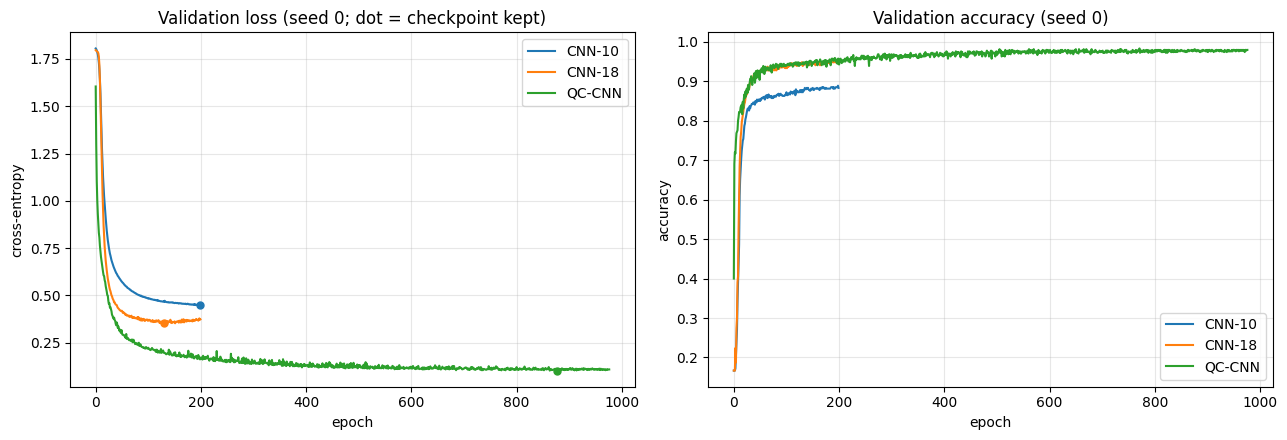

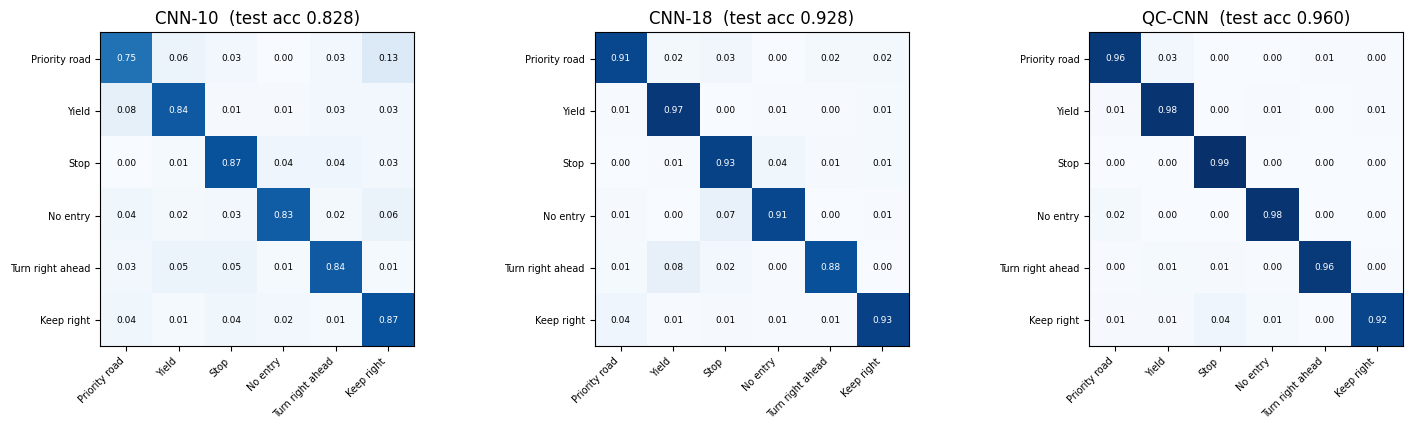

Per-class report - QC-CNN (seed 0)
                  precision    recall  f1-score   support

   Priority road      0.966     0.959     0.963       690
           Yield      0.959     0.978     0.968       720
            Stop      0.890     0.993     0.939       270
        No entry      0.957     0.981     0.968       360
Turn right ahead      0.967     0.962     0.964       210
      Keep right      0.986     0.917     0.950       690

        accuracy                          0.960      2940
       macro avg      0.954     0.965     0.959      2940
    weighted avg      0.961     0.960     0.960      2940



In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for name, runs in results.items():
    h = runs[0]["hist"]
    ax[0].plot(h["va_loss"], label=name)
    ax[1].plot(h["va_acc"],  label=name)
    b = int(np.argmin(h["va_loss"]))
    ax[0].plot(b, h["va_loss"][b], "o", ms=5, color=ax[0].lines[-1].get_color())
ax[0].set(title="Validation loss (seed 0; dot = checkpoint kept)", xlabel="epoch",
          ylabel="cross-entropy")
ax[1].set(title="Validation accuracy (seed 0)", xlabel="epoch", ylabel="accuracy")
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, len(results), figsize=(5*len(results), 4.4))
for a, (name, runs) in zip(np.atleast_1d(axes), results.items()):
    cm = confusion_matrix(yte, runs[0]["preds"], normalize="true")
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1)
    a.set(title=f"{name}  (test acc {runs[0]['test_acc']:.3f})",
          xticks=range(N_CLASSES), yticks=range(N_CLASSES))
    a.set_xticklabels(CFG["CLASS_NAMES"], rotation=45, ha="right", fontsize=7)
    a.set_yticklabels(CFG["CLASS_NAMES"], fontsize=7)
    for i in range(N_CLASSES):
        for j in range(N_CLASSES):
            a.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=6.5,
                   color="white" if cm[i,j] > .5 else "black")
plt.tight_layout(); plt.show()

print("Per-class report - QC-CNN (seed 0)")
print(classification_report(yte, results["QC-CNN"][0]["preds"],
                            target_names=CFG["CLASS_NAMES"], digits=3))

### 7b. What the extra resolution bought

The FRQI overlap of two images is $\langle\Psi_a|\Psi_b\rangle = \frac{1}{2^{2n}}\sum_{x,y}
\cos(\theta_a - \theta_b)$, so the encoding is injective and orthogonal at the extremes
($v=0$ vs $v=1$) — the angle map itself loses nothing. What limits the model is how much
class-distinguishing structure survives the ROI crop and the downscale. This cell measures that
directly at the current resolution: mean within-class and between-class
$|\langle\Psi_a|\Psi_b\rangle|^2$, and what the optional intensity maps do to it.

Run it with `CFG["IMG_SIZE"] = 8` and again at 16 to quantify the gain from the larger input.

In [21]:
def frqi_separability(X, y, mode, n_per_class=120, seed=0):
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.where(y == c)[0],
                                     min(n_per_class, int((y == c).sum())), replace=False)
                          for c in range(int(y.max())+1)])
    S = frqi_state(X[idx], mode).astype(np.float64)
    lab = y[idx]
    F = (S @ S.T) ** 2                                    # fidelity |<Psi_a|Psi_b>|^2
    same = lab[:, None] == lab[None, :]
    off  = ~np.eye(len(lab), dtype=bool)
    return dict(mode=mode, size=f"{CFG['IMG_SIZE']}x{CFG['IMG_SIZE']}",
                dyn_range=float(np.mean(X[idx].max((1,2)) - X[idx].min((1,2)))),
                within=float(F[same & off].mean()),
                between=float(F[~same].mean()),
                margin=float(F[same & off].mean() - F[~same].mean()))

sep = pd.DataFrame([frqi_separability(Xtr, ytr, m) for m in ["paper", "minmax", "equalize"]])
print("FRQI state geometry (a larger margin means the encoding separates the classes more")
print(" before a single trainable gate is applied)\n")
display(sep)

shape_cls = [i for i, nm in enumerate(CFG["CLASS_NAMES"])
             if nm in ("Stop", "Yield", "No entry", "Priority road")]
if len(shape_cls) > 1:
    msk = np.isin(ytr, shape_cls)
    remap = {c: i for i, c in enumerate(shape_cls)}
    ys = np.array([remap[v] for v in ytr[msk]])
    print("\nRestricted to the shape-confusable classes "
          f"{[CFG['CLASS_NAMES'][c] for c in shape_cls]}")
    display(pd.DataFrame([frqi_separability(Xtr[msk], ys, m)
                          for m in ["paper", "minmax", "equalize"]]))

FRQI state geometry (a larger margin means the encoding separates the classes more
 before a single trainable gate is applied)



,mode,size,dyn_range,within,between,margin
0,paper,16x16,0.615294,0.779661,0.746119,0.033542
1,minmax,16x16,0.615294,0.750215,0.678235,0.071980
2,equalize,16x16,0.615294,0.754915,0.667479,0.087436



Restricted to the shape-confusable classes ['Priority road', 'Yield', 'Stop', 'No entry']


,mode,size,dyn_range,within,between,margin
0,paper,16x16,0.632819,0.766686,0.729061,0.037625
1,minmax,16x16,0.632819,0.738943,0.655750,0.083194
2,equalize,16x16,0.632819,0.757971,0.662572,0.095399


## 8. Ablation A — quantum gates and measurement operators (paper Section V-B, Table V)

Paper protocol: a **balanced 2-category** task, sweeping the rotation gate
($U3$ / $R_X$ / $R_Y$) against the measurement basis (X / Y / Z / XYZ).

Set `RUN_ABLATION_GATES = True` to run it (12 trainings x 2 seeds). Each uses the full
`EPOCHS_Q_ABL` budget with early stopping — a short fixed budget makes every cell of this table
look the same, because the models are still in the linear part of their loss curve.

In [22]:
RUN_ABLATION_GATES = False

if RUN_ABLATION_GATES:
    bin_cls = [14, 17]                                   # Stop vs. No entry
    Xb, yb = load_split("Train.csv", CFG["ROOT"], bin_cls, CFG["IMG_SIZE"], 500, 0)
    Xbt, ybt = load_split("Test.csv", CFG["ROOT"], bin_cls, CFG["IMG_SIZE"])
    nb_ = len(Xb); cut = int(.85*nb_); perm = np.random.default_rng(0).permutation(nb_)
    d = ((frqi_state(Xb[perm[:cut]]), yb[perm[:cut]]),
         (frqi_state(Xb[perm[cut:]]), yb[perm[cut:]]),
         (frqi_state(Xbt), ybt))
    rows = []
    for gate in ["U3", "RY", "RX"]:
        for bases in [("X",), ("Y",), ("Z",), ("X","Y","Z")]:
            accs, eps = [], []
            for s in [0, 1]:
                m = QCCNN(2, gate, bases, seed=s)
                r = train(m, d, CFG["EPOCHS_Q_ABL"], CFG["LR_Q"], CFG["BATCH"], s, verbose=0,
                          patience=CFG["PATIENCE_Q"], min_delta=CFG["MIN_DELTA"], schedule=CFG["LR_SCHEDULE"],
                          ckpt=f"abl_gate_{gate}_{''.join(bases)}_s{s}")
                accs.append(r["test_acc"]); eps.append(r["epochs_run"])
            rows.append(dict(Gate=gate, Measurement="".join(bases),
                             Params=sum(p.numel() for p in m.parameters()),
                             Epochs=int(np.mean(eps)),
                             TestAcc=f"{np.mean(accs):.3f} +/- {np.std(accs):.3f}"))
            print(rows[-1])
    adf = pd.DataFrame(rows)
    display(adf.pivot(index="Gate", columns="Measurement", values="TestAcc")[["X","Y","Z","XYZ"]])
    print(f"Epochs actually used before early stopping (budget {CFG['EPOCHS_Q_ABL']}):")
    display(adf.pivot(index="Gate", columns="Measurement", values="Epochs")[["X","Y","Z","XYZ"]])

## 9. Ablation B — model structure (paper Section V-C, Table VI)

Number of quantum convolution layers $m$ and kernels $2^k$ per layer. Changing $k$ adds $q_K$
qubits; changing $m$ adds $q_R$ qubits — total qubits $=2n+k+m+1$. At $n=4$ the choice of $m$ also
sets the size of the surviving feature map, and therefore the width of the dense head:

| m | final map | basis states | XYZ features | qubits (k=1) |
|---|---|---|---|---|
| 2 | 4x4 x 2 | 32 | 96 | 12 |
| **3** | **2x2 x 2** | **8** | **24** | **13** |
| 4 | 1x1 x 2 | 2 | 6 | 14 |

`QCCNN` is already parameterised by $(n, m, k)$ and the fast engine handles any of these layouts,
so the sweep just constructs models. **Cost warning:** every extra qubit doubles the state
vector, so the $m=4$ and $k=2$ rows are roughly 2-4x slower per epoch than the default.

In [23]:
RUN_ABLATION_STRUCTURE = False

if RUN_ABLATION_STRUCTURE:
    rows = []
    layouts = [(m_, k_) for (m_, k_) in [(M_CONV-1, K_QK), (M_CONV, K_QK),
                                         (M_CONV, K_QK+1), (M_CONV+1, K_QK)]
               if 1 <= m_ <= N_BITS]
    for (m_, k_) in layouts:
        accs, eps = [], []
        for s in [0, 1]:
            mod = QCCNN(N_CLASSES, seed=s, n=N_BITS, m=m_, k=k_)
            r = train(mod, QUANTUM_DATA, CFG["EPOCHS_Q_ABL"], CFG["LR_Q"], CFG["BATCH"], s,
                      verbose=0, patience=CFG["PATIENCE_Q"], min_delta=CFG["MIN_DELTA"], schedule=CFG["LR_SCHEDULE"],
                      ckpt=f"abl_struct_n{N_BITS}m{m_}k{k_}_s{s}")
            accs.append(r["test_acc"]); eps.append(r["epochs_run"])
        side = 2 ** (N_BITS - m_)
        rows.append(dict(ConvLayers=m_, Kernels=2**k_, Qubits=mod.n_wires,
                         Map=f"{side}x{side}", Features=mod.n_features,
                         Params=sum(p.numel() for p in mod.parameters()),
                         Epochs=int(np.mean(eps)),
                         TestAcc=f"{np.mean(accs):.3f} +/- {np.std(accs):.3f}"))
        print(rows[-1])
    display(pd.DataFrame(rows))

## 10. Ablation C — noise (paper Section V-D, Table VII)

Two kinds of noise, exactly as the paper defines them:

1. **Data noise** — additive Gaussian perturbation on the downscaled images. This runs on the
   full 16x16 model and is cheap, because it only re-evaluates already-trained weights.
2. **Model noise** — an extra Pauli-X/Y/Z gate applied with error rate $p\in\{0.01,0.05,0.10\}$
   on each measured qubit (a depolarizing channel on `default.mixed`).

**Model noise cannot be simulated at 13 qubits.** A density matrix is $2^{13}\times2^{13}$
complex numbers — about 0.5 GB *per sample*, so even a batch of 2 does not fit. The cell
therefore runs the model-noise study at the paper's original **8x8 / m=2 / 10-qubit**
configuration, where the density matrix is 1024x1024, and says so in its output. That is a
deliberate, reported reduction: state it in your write-up rather than presenting it as a 16x16
result.

In [24]:
RUN_NOISE_DATA  = False
RUN_NOISE_MODEL = False

def rebuild(name, seed):
    if name == "QC-CNN":
        return QCCNN(N_CLASSES, seed=seed)
    return CNN(N_CLASSES, CNN_WIDTHS[name], seed=seed)

if RUN_NOISE_DATA:
    rows = []
    for sigma in [0.0, 0.05, 0.10, 0.20]:
        Xn = np.clip(Xte + np.random.default_rng(0).normal(0, sigma, Xte.shape), 0, 1)
        Sn = frqi_state(Xn)
        r = {"sigma": sigma}
        for name, runs_ in results.items():
            Xin = Sn if name == "QC-CNN" else Xn[:, None]
            accs = []
            for s, run in zip(CFG["SEEDS"], runs_):
                mod = rebuild(name, s); mod.load_state_dict(run["state"])
                accs.append(evaluate(mod, Xin, yte)[1])
            r[name] = f"{np.mean(accs):.3f}"
        rows.append(r); print(r)
    display(pd.DataFrame(rows))

if RUN_NOISE_MODEL:
    # reduced configuration - see the note above
    NZ_N, NZ_M, NZ_K, NZ_SIZE = 3, 2, 1, 8
    print(f"model-noise study at the reduced {NZ_SIZE}x{NZ_SIZE} / m={NZ_M} / "
          f"{2*NZ_N+1+NZ_K+NZ_M}-qubit configuration (density-matrix simulation)")
    Xa, ya = load_split("Train.csv", CFG["ROOT"], CFG["CLASSES"], NZ_SIZE, 100, 0)
    Xb_, yb_ = load_split("Test.csv", CFG["ROOT"], CFG["CLASSES"], NZ_SIZE, 100, 0)
    cut = int(.85*len(Xa)); perm = np.random.default_rng(0).permutation(len(Xa))
    dz = ((frqi_state(Xa[perm[:cut]]), ya[perm[:cut]]),
          (frqi_state(Xa[perm[cut:]]), ya[perm[cut:]]),
          (frqi_state(Xb_), yb_))
    rows = []
    for p in [0.0, 0.01, 0.05, 0.10]:
        mod = QCCNN(N_CLASSES, noise_p=p, seed=0, n=NZ_N, m=NZ_M, k=NZ_K)
        acc = train(mod, dz, 20, CFG["LR_Q"], 20, 0, verbose=0,
                    schedule=CFG["LR_SCHEDULE"])["test_acc"]
        rows.append(dict(error_rate=p, Qubits=mod.n_wires, TestAcc=f"{acc:.3f}"))
        print(rows[-1])
    display(pd.DataFrame(rows))

## 11. Significance test across 5 GTSRB sub-benchmarks (paper Section V-A, Table IV)

The paper runs a **one-sided Wilcoxon signed-rank test** over its 5 EO datasets:
$H_0$: QC-CNN's mean test accuracy $\le$ competitor's; $H_1$: QC-CNN is better.

GTSRB is one dataset, so to reproduce the test we build **5 sub-benchmarks** from disjoint /
distinct GTSRB class groups and treat them as the 5 paired observations. Enable the flag to run it
end to end (this is the long cell — roughly 5x the Stage 1+2 runtime).

In [25]:
RUN_MULTI_BENCHMARK = False

SUBSETS = {
    "shapes-3":     ([12, 13, 14],         ["Priority", "Yield", "Stop"]),
    "prohibit-3":   ([15, 17, 32],         ["No vehicles", "No entry", "End limits"]),
    "speed-3":      ([1, 2, 5],            ["30", "50", "80"]),
    "direction-4":  ([33, 34, 35, 38],     ["Right", "Left", "Ahead", "Keep right"]),
    "warning-4":    ([18, 25, 27, 28],     ["Caution", "Road work", "Pedestrian", "Children"]),
}

if RUN_MULTI_BENCHMARK:
    bench, bench_ep = {}, {}
    for bname, (cls, names) in SUBSETS.items():
        Xa, ya = load_split("Train.csv", CFG["ROOT"], cls, CFG["IMG_SIZE"], 400, 0)
        Xb_, yb_ = load_split("Test.csv", CFG["ROOT"], cls, CFG["IMG_SIZE"])
        perm = np.random.default_rng(0).permutation(len(Xa)); cut = int(.85*len(Xa))
        tr, va = perm[:cut], perm[cut:]
        cdat = ((Xa[tr][:,None], ya[tr]), (Xa[va][:,None], ya[va]), (Xb_[:,None], yb_))
        qdat = ((frqi_state(Xa[tr]), ya[tr]), (frqi_state(Xa[va]), ya[va]), (frqi_state(Xb_), yb_))
        row = {}
        for nm, widths in CLASSICAL_MODELS:
            row[nm] = np.mean([train(CNN(len(cls), widths, seed=s), cdat, CFG["EPOCHS_C"],
                                     CFG["LR_C"], CFG["BATCH"], s, verbose=0)["test_acc"]
                               for s in CFG["SEEDS"]])
        qres = [train(QCCNN(len(cls), seed=s), qdat,
                      CFG["EPOCHS_Q"], CFG["LR_Q"], CFG["BATCH"], s, verbose=0,
                      patience=CFG["PATIENCE_Q"], min_delta=CFG["MIN_DELTA"], schedule=CFG["LR_SCHEDULE"],
                      ckpt=f"bench_{bname}_s{s}", time_budget=CFG["TIME_BUDGET_Q"])
                for s in CFG["SEEDS"]]
        row["QC-CNN"] = np.mean([r["test_acc"] for r in qres])
        bench[bname] = row; bench_ep[bname] = int(np.mean([r["epochs_run"] for r in qres]))
        print(bname, {k: f"{v:.3f}" for k, v in row.items()},
              f"| QC-CNN epochs {bench_ep[bname]}")

    bdf = pd.DataFrame(bench).T
    bdf["QC-CNN epochs"] = pd.Series(bench_ep)
    display(bdf)
    for comp, _ in CLASSICAL_MODELS:
        stat, p = wilcoxon(bdf["QC-CNN"], bdf[comp], alternative="greater")
        print(f"QC-CNN vs {comp}: one-sided Wilcoxon p = {p:.4f}"
              f"  -> {'reject H0 (QC-CNN better)' if p < 0.05 else 'insufficient evidence'}")

## 12. Efficiency / scalability analysis (paper Section VI)

Reproduces Tables VIII and IX for this GTSRB configuration. The interesting column is the last
one: going from 8x8 to 16x16 **quadruples** the classical convolution cost and adds **two**
qubits, while the number of quantum convolution gates per layer does not change at all.

In [26]:
n, k, m = N_BITS, K_QK, M_CONV
eff = pd.DataFrame([
    dict(Aspect="Convolution operations (per layer)",
         QC_CNN=f"{2**(k+2)} controlled-{CFG['GATE']} gates  (size independent)",
         CNN=f"O(2^(k+2n)) = {2**(k+2*n)} MACs"),
    dict(Aspect="Trainable params (per conv layer, 2^k kernels of 2x2)",
         QC_CNN=f"{3*4*2**k} (U3)  /  {4*2**k} (RX,RY)", CNN=f"{4*2**k} (+bias)"),
    dict(Aspect="Encoding layer gates",
         QC_CNN=f"{2*n} H + {2**(2*n)} multi-controlled RY", CNN="-"),
    dict(Aspect="Measurement circuit runs",
         QC_CNN=f"O(2^(2n-2m+k+1)) = O({2**(2*n-2*m+k+1)})", CNN="-"),
])
display(eff)

qub = pd.DataFrame([
    dict(Layer="Encoding (qL + qC)", Qubits=2*n+1, Formula="2n + 1 = 2log2(N) + 1"),
    dict(Layer="Kernel index (qK)",  Qubits=k,     Formula="k = log2(#kernels per layer)"),
    dict(Layer="Feature maps (qR)",  Qubits=m,     Formula="m = #conv layers"),
    dict(Layer="TOTAL (grayscale)",  Qubits=2*n+k+m+1, Formula="2n + k + m + 1"),
    dict(Layer="TOTAL (RGB, MCQI)",  Qubits=2*n+k+m+3, Formula="2n + k + m + 3"),
])
display(qub)

# scaling: m grows like log2(N) to keep the final feature map at 2x2
N = np.array([8, 16, 32, 64, 128, 256])
nb = np.log2(N).astype(int)
m_of_N = nb - 1                                   # keep a 2x2 surviving map
cmp = pd.DataFrame({
    "Image NxN":                       [f"{v}x{v}" for v in N],
    "n = log2(N)":                     nb,
    "m (for a 2x2 final map)":         m_of_N,
    "QC-CNN qubits (2n+k+m+1)":        2*nb + k + m_of_N + 1,
    "QC-CNN conv gates per layer":     [2**(k+2)]*len(N),
    "QC-CNN conv gates total":         (2**(k+2))*m_of_N,
    "CNN conv MACs (first layer)":     (2**k)*N*N,
})
display(cmp)
print(f"\nThis notebook is the {CFG['IMG_SIZE']}x{CFG['IMG_SIZE']} row: "
      f"n={n}, m={m}, k={k} -> {2*n+k+m+1} qubits, "
      f"{(2**(k+2))*m} controlled-{CFG['GATE']} gates in the whole quantum section.")

,Aspect,QC_CNN,CNN
0,Convolution operations (per layer),8 controlled-U3 gates (size independent),O(2^(k+2n)) = 512 MACs
1,"Trainable params (per conv layer, 2^k kernels ...","24 (U3) / 8 (RX,RY)",8 (+bias)
2,Encoding layer gates,8 H + 256 multi-controlled RY,-
3,Measurement circuit runs,O(2^(2n-2m+k+1)) = O(16),-


,Layer,Qubits,Formula
0,Encoding (qL + qC),9,2n + 1 = 2log2(N) + 1
1,Kernel index (qK),1,k = log2(#kernels per layer)
2,Feature maps (qR),3,m = #conv layers
3,TOTAL (grayscale),13,2n + k + m + 1
4,"TOTAL (RGB, MCQI)",15,2n + k + m + 3


,Image NxN,n = log2(N),m (for a 2x2 final map),QC-CNN qubits (2n+k+m+1),QC-CNN conv gates per layer,QC-CNN conv gates total,CNN conv MACs (first layer)
0,8x8,3,2,10,8,16,128
1,16x16,4,3,13,8,24,512
2,32x32,5,4,16,8,32,2048
3,64x64,6,5,19,8,40,8192
4,128x128,7,6,22,8,48,32768
5,256x256,8,7,25,8,56,131072



This notebook is the 16x16 row: n=4, m=3, k=1 -> 13 qubits, 24 controlled-U3 gates in the whole quantum section.


## 13. What to write up

* **Why 16x16 and m=3.** Each quantum convolution layer consumes one $(x,y)$ bit pair, so the
  depth is tied to the resolution: $m = n-1$ keeps the surviving feature map at $2\times2$ and
  therefore the measurement head at 24 features. Going 8x8 -> 16x16 costs **2 qubits and one
  extra layer** (10 -> 13 qubits, 4 -> 6 quantum kernels, 48 -> 72 quantum parameters) while a
  classical convolution layer's cost quadruples. That asymmetry — Table in section 12 — is the
  paper's central efficiency claim, and it is much more visible at 16x16 than at 8x8.

* **Stage 1 vs Stage 2**: the QC-CNN reaches 24 features with 6 quantum kernels against the
  feature-matched classical model's 18. Report kernels, features *and* parameters together.

* **Generalisation gap** (`Gap` column): the paper's evidence for lower overfitting is the small
  train-test difference, not just raw accuracy. Report it.

* **Report the epoch column.** With early stopping, a model that stopped at, say, epoch 180 of a
  500 budget converged; one that used all 500 did not, and its accuracy is a lower bound. Do not
  compare a converged model against an epoch-starved one.

* **Honest caveats to state in your report**:
  * the simulator is noiseless and the encoding layer is state-prepared rather than
    gate-synthesised, so the quoted speed-up is a *circuit-complexity* argument (section 12), not
    wall-clock. On a simulator the quantum model remains far slower than the classical one.
  * the quantum section is executed by the torch engine of section 4a, not by `default.qubit`;
    section 4d is the evidence that this is the same circuit, and it should be run and its
    output kept.
  * `CFG["FEATURE_SCALE"] = 8.0` is an exact reparameterisation of the dense layer, not an
    architectural change, but it does change the optimisation trajectory — say so.
  * the model-noise ablation runs at a reduced 8x8 / 10-qubit configuration (section 10).
  * GTSRB at 16x16 **grayscale** still discards colour, which is highly informative for traffic
    signs — that is a limitation of the $2n+1$ FRQI budget, and is exactly why the paper's MCQI
    extension (+3 qubits for RGB, i.e. 16 qubits here) is the natural next step.

* **If accuracy is low**: raise `MAX_PER_CLASS`, check the epoch column before touching anything
  else, and use section 7b to see whether the encoded states are separable at all before blaming
  the quantum layers.